# LAB 10 — K-Means Clustering
## Finding Customer Segments, Choosing K and Avoiding the Traps on Real Data

## Student Information
- **Name:** Usman
- **Student ID:**
- **Section:**
- **GitHub:** https://github.com/usmanasad-droid
- **Kaggle:** https://www.kaggle.com/code/usmanasad0/
- **Dataset:** Mall Customers (Kaggle) + Wine (UCI)
- **Dataset Source:** https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python and https://archive.ics.uci.edu/dataset/109/wine

### Before You Start
- You studied K-Means in the lecture. This notebook does not teach it again; it makes you use it, test it and question it.
- There is **no target column**: no train/test split and no accuracy. Judge results by distances, silhouette, plots and common sense.
- Use `SEED = 42`. Write an interpretation under every table and plot. Place `Mall_Customers.csv` in the same folder as this notebook.
- `from sklearn.datasets import load_wine` loads the Wine data (no download needed).


---

## Part 0 — Setup and First Look (10 minutes)

Today there is no target column. The Mall Customers data has no 'right answer' for each customer, so we do not split into train and test and we cannot use accuracy. You will find groups with K-Means (your lecture) and judge them by distance, silhouette and common sense.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Unsupervised learning | Learning from data that has no labels. The goal is to find structure (groups), not to predict a column. | `No y, no train_test_split.` |
| Cluster | A group of points that are close to each other and far from the other groups. | `model.labels_ gives the cluster number of every row.` |
| Feature | One column used to describe each row (here Age, Income, Spending). | `df[['Income','Spending']].values` |


**First cell:** import everything you need (NumPy, Pandas, Matplotlib, KMeans, StandardScaler, PCA, load_wine, silhouette_score, silhouette_samples, adjusted_rand_score) and set `SEED = 42`.

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.datasets import load_wine

SEED = 42

### Task 0.1 — Load and check the data

Load Mall_Customers.csv and understand it in one cell.

1. Load the CSV. Rename 'Annual Income (k$)' to Income and 'Spending Score (1-100)' to Spending (shorter names).
2. Print the shape, the number of missing values, the number of duplicate rows and the count of each Gender.
3. Show describe() for Age, Income and Spending.


In [53]:
df = pd.read_csv('Mall_Customers.csv')
df = df.rename(columns={
    'Annual Income (k$)': 'Income',
    'Spending Score (1-100)': 'Spending'
})
print(f"Shape of dataset: {df.shape}")
print(f"Total missing values:\n{df.isnull().sum()}\n")
print(f"Duplicate rows: {df.duplicated().sum()}\n")
print(f"Gender counts:\n{df['Gender'].value_counts()}\n")

df[['Age', 'Income', 'Spending']].describe()

Shape of dataset: (200, 5)
Total missing values:
CustomerID    0
Gender        0
Age           0
Income        0
Spending      0
dtype: int64

Duplicate rows: 0

Gender counts:
Gender
Female    112
Male       88
Name: count, dtype: int64



,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Task 0.2 — Look at the data before clustering

Use your eyes first: draw three scatter plots side by side.

1. Draw Spending vs Income, Spending vs Age and Income vs Age (one row of three plots, axis labels and titles).


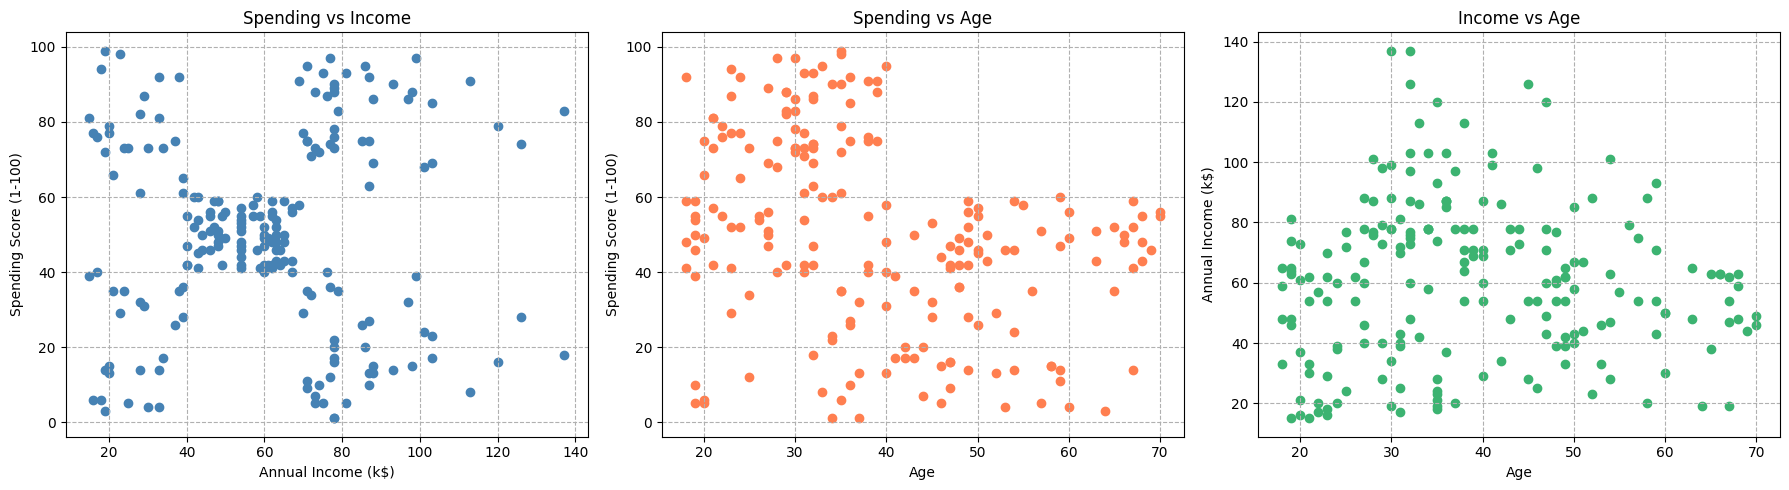

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Spending vs Income
axes[0].scatter(df['Income'], df['Spending'], c='steelblue')
axes[0].set_title('Spending vs Income')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].grid(True, linestyle='--')

# Plot 2: Spending vs Age
axes[1].scatter(df['Age'], df['Spending'], c='coral')
axes[1].set_title('Spending vs Age')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Spending Score (1-100)')
axes[1].grid(True, linestyle='--')

# Plot 3: Income vs Age
axes[2].scatter(df['Age'], df['Income'], c='mediumseagreen')
axes[2].set_title('Income vs Age')
axes[2].set_xlabel('Age')
axes[2].set_ylabel('Annual Income (k$)')
axes[2].grid(True, linestyle='--')

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) How many groups can you see by eye in each of the three plots? Which plot shows the groups most clearly?

(b) Why can we not use accuracy or a train/test split to judge a clustering result?



**Your answers:**

(a) Spending vs income: 5 groups \
Spending vs age: 2 groups \
Income vs age: no groups, continous data \
The Spending vs Income plot shows the groups most clearly, 5 distinct, well separated clusters with empty space between them


(b) Accuracy needs a "correct answer" (label) to see if the model is right or wrong. In clustering, there are no true labels or answers in the data, so accuracy cannot be calculated \
A train/test split checks how well a model predicts on new unseen data. Since we are only trying to find hidden groups inside our existing data, not predicting an outcome, there is no target to split or test against

---

## Part 1 — K-Means From Scratch (35 minutes)

In the lecture you did K-Means by hand. Here you turn your pen-and-paper steps into code, check your answers against the lecture slides, and then build your own K-Means function and compare it with scikit-learn. Using KMeans() inside your own function is not allowed.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| K | The number of clusters. You choose it before running. | `KMeans(n_clusters=5)` |
| Centroid | The centre (mean) of a cluster. It is a point, not always a real row. | `model.cluster_centers_` |
| Distance | 1 feature: |x - m|. 2 or more features: Euclidean, sqrt of the sum of squared differences. | `np.abs(a-b)  or  np.sqrt(((a-b)**2).sum(axis=1))` |
| Assign step | Give each point to its nearest centroid. | `d.argmin(axis=1)` |
| Update step | Move each centroid to the mean of the points assigned to it. | `X[labels==k].mean(axis=0)` |
| Convergence | Stop when no point changes cluster (centroids stop moving). | `np.allclose(new_c, c)` |
| Inertia | Sum of squared distances from every point to its own centroid. Smaller = tighter clusters. | `model.inertia_` |
| Broadcasting | NumPy trick: x[:, None] - m[None, :] gives every point-to-centroid difference in one line. | `x[:, None, :] - C[None, :, :]` |


### Task 1.1 — Lecture Example 1 in code (one feature)

Reproduce the 9-number example from the lecture (2, 4, 10, 12, 3, 20, 30, 11, 25) with K = 2 and starting centroids 4 and 11.

1. Write a loop that, in every iteration, computes the distances, assigns the clusters, updates the centroids and prints both clusters and the new centroids.
2. Stop when no centroid changes. Print the final centroids and the inertia.
3. Compare with the lecture slides (final centroids 7 and 25, inertia 150).

**Hints:**
- Distance matrix: np.abs(x[:, None] - m[None, :]) has shape (9, 2).
- Cluster of each point: dist.argmin(axis=1).


In [55]:
# YOUR CODE HERE
x = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25], dtype=float)
m = np.array([4, 11], dtype=float)

iteration = 1
while True:
  # Compute absolute distances using NumPy broadcasting: shape (9, 2)
  dist = np.abs(x[:, None] - m[None, :])

  # Assign each point to the closest centroid (0 or 1)
  labels = dist.argmin(axis=1)

  # Update centroids by computing the mean of assigned points
  new_m = np.array([x[labels == k].mean() for k in range(len(m))])

  # Print iteration details
  print(f"Iteration: {iteration}")
  print(f"Cluster 0 points: {x[labels == 0].tolist()}")
  print(f"Cluster 1 points: {x[labels == 1].tolist()}")
  print(f"Updated Centroids: {new_m.round(4).tolist()}\n")

  # Check convergence: stop when centroids do not change
  if np.allclose(new_m, m):
      break

  m = new_m
  iteration += 1

inertia = np.sum((x - m[labels]) ** 2)

print(f"Final Centroids: {m}")
print(f"Final Inertia: {inertia}")

Iteration: 1
Cluster 0 points: [2.0, 4.0, 3.0]
Cluster 1 points: [10.0, 12.0, 20.0, 30.0, 11.0, 25.0]
Updated Centroids: [3.0, 18.0]

Iteration: 2
Cluster 0 points: [2.0, 4.0, 10.0, 3.0]
Cluster 1 points: [12.0, 20.0, 30.0, 11.0, 25.0]
Updated Centroids: [4.75, 19.6]

Iteration: 3
Cluster 0 points: [2.0, 4.0, 10.0, 12.0, 3.0, 11.0]
Cluster 1 points: [20.0, 30.0, 25.0]
Updated Centroids: [7.0, 25.0]

Iteration: 4
Cluster 0 points: [2.0, 4.0, 10.0, 12.0, 3.0, 11.0]
Cluster 1 points: [20.0, 30.0, 25.0]
Updated Centroids: [7.0, 25.0]

Final Centroids: [ 7. 25.]
Final Inertia: 150.0


### Task 1.2 — Lecture Example 2 in code (two features)

Do the height/weight example: P1 (185, 72), P2 (170, 56), P3 (168, 60), P4 (179, 68), P5 (182, 72), P6 (188, 77). K = 2, start with P1 and P2.

1. Use Euclidean distance and the same loop idea. Print the cluster of every point and the centroids per iteration.
2. Print the final distance table and check one value by hand (the lecture shows d(P3, M2) = 4.47 in the first iteration).


In [56]:
X = np.array([
    [185, 72],  # P1
    [170, 56],  # P2
    [168, 60],  # P3
    [179, 68],  # P4
    [182, 72],  # P5
    [188, 77]   # P6
], dtype=float)

point_names = ['P1', 'P2', 'P3', 'P4', 'P5', 'P6']

# Starting centroids: P1 and P2
C = np.array([
    [185.0, 72.0],  # M1
    [170.0, 56.0]   # M2
])

iteration = 1
while True:
  # 2D Euclidean distance via broadcasting:
  # X[:, None, :] has shape (6, 1, 2)
  # C[None, :, :] has shape (1, 2, 2)
  # Difference has shape (6, 2, 2) -> norm over axis=2 gives shape (6, 2)
  dist = np.linalg.norm(X[:, None, :] - C[None, :, :], axis=2)

  labels = dist.argmin(axis=1)

  # In iteration 1, print the distance table to verify d(P3, M2) = 4.47
  if iteration == 1:
      df_iter1 = pd.DataFrame(dist, index=point_names, columns=['d(P, M1)', 'd(P, M2)'])
      print("Iteration 1 Distance Matrix:")
      print(df_iter1.round(2))
      print()

  # Update centroids
  new_C = np.array([X[labels == k].mean(axis=0) for k in range(len(C))])

  # Print iteration summary
  print(f"Iteration {iteration}:")
  for name, lbl in zip(point_names, labels):
      print(f"{name} -> Cluster {lbl + 1} (M{lbl + 1})")
  print(f"New Centroids:\n M1: {new_C[0].round(2)}\n M2: {new_C[1].round(2)}\n")

  # Check convergence
  if np.allclose(new_C, C):
      break

  C = new_C
  iteration += 1

# Final Distance Table
final_dist = np.linalg.norm(X[:, None, :] - C[None, :, :], axis=2)
df_final = pd.DataFrame(final_dist, index=point_names, columns=['d(P, Final_M1)', 'd(P, Final_M2)'])
df_final['Assigned Cluster'] = [f"Cluster {l + 1}" for l in labels]

print("Final Distance Table")
print(df_final.round(2))

Iteration 1 Distance Matrix:
    d(P, M1)  d(P, M2)
P1      0.00     21.93
P2     21.93      0.00
P3     20.81      4.47
P4      7.21     15.00
P5      3.00     20.00
P6      5.83     27.66

Iteration 1:
P1 -> Cluster 1 (M1)
P2 -> Cluster 2 (M2)
P3 -> Cluster 2 (M2)
P4 -> Cluster 1 (M1)
P5 -> Cluster 1 (M1)
P6 -> Cluster 1 (M1)
New Centroids:
 M1: [183.5   72.25]
 M2: [169.  58.]

Iteration 2:
P1 -> Cluster 1 (M1)
P2 -> Cluster 2 (M2)
P3 -> Cluster 2 (M2)
P4 -> Cluster 1 (M1)
P5 -> Cluster 1 (M1)
P6 -> Cluster 1 (M1)
New Centroids:
 M1: [183.5   72.25]
 M2: [169.  58.]

Final Distance Table
    d(P, Final_M1)  d(P, Final_M2) Assigned Cluster
P1            1.52           21.26        Cluster 1
P2           21.13            2.24        Cluster 2
P3           19.76            2.24        Cluster 2
P4            6.19           14.14        Cluster 1
P5            1.52           19.10        Cluster 1
P6            6.54           26.87        Cluster 1


### Task 1.3 — Write your own K-Means function

Write my_kmeans(X, init_centroids, max_iter=100) for any number of features.

1. Return four things: labels, final centroids, inertia and the number of iterations.
2. Test it on Example 1: it must give centroids 7 and 25 and inertia 150.
3. Think about what to do if a cluster ends up empty (keep its old centroid).


In [57]:
def my_kmeans(X, init_centroids, max_iter=100):
    # Ensure inputs are 2D float arrays (works for 1 feature or any number of features)
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]

    centroids = np.asarray(init_centroids, dtype=float)
    if centroids.ndim == 1:
        centroids = centroids[:, None]

    K = centroids.shape[0]
    num_iterations = 0

    for it in range(1, max_iter + 1):
        num_iterations = it

        # 1. Compute Euclidean distance matrix: shape (N, K)
        # Using np.linalg.norm over the feature dimension (axis=2)
        dist = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)

        # 2. Assign each point to the closest centroid
        labels = dist.argmin(axis=1)

        # 3. Update centroids (keep old centroid if a cluster ends up empty)
        new_centroids = np.zeros_like(centroids)
        for k in range(K):
            cluster_points = X[labels == k]
            if len(cluster_points) > 0:
                new_centroids[k] = cluster_points.mean(axis=0)
            else:
                new_centroids[k] = centroids[k]  # Keep old centroid if empty

        # 4. Check for convergence (centroids stop moving)
        if np.allclose(new_centroids, centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    # Compute final inertia (Sum of squared distances from points to their assigned centroid)
    assigned_centroids = centroids[labels]
    inertia = np.sum((X - assigned_centroids) ** 2)

    # Flatten centroids back if input was 1D
    if centroids.shape[1] == 1:
        centroids = centroids.ravel()

    return labels, centroids, inertia, num_iterations

In [58]:
# 9 numbers from Example 1
x_ex1 = np.array([2, 4, 10, 12, 3, 20, 30, 11, 25])
init_c_ex1 = np.array([4.0, 11.0])

labels, final_centroids, inertia, n_iter = my_kmeans(x_ex1, init_c_ex1)

print(f"Labels:          {labels}")
print(f"Final Centroids: {final_centroids}")
print(f"Inertia:         {inertia}")
print(f"Iterations:      {n_iter}")

Labels:          [0 0 0 0 0 1 1 0 1]
Final Centroids: [ 7. 25.]
Inertia:         150.0
Iterations:      4


### Task 1.4 — Check your function against scikit-learn

Run your function and KMeans on the same data with the same starting centroids and compare.

1. Use X2 = Income and Spending (200 x 2). Take the first 5 rows as the starting centroids.
2. Run my_kmeans. Run KMeans(n_clusters=5, init=<your 5 rows>, n_init=1, tol=0, algorithm='lloyd').
3. Compare iterations, inertia, labels and centroids.


In [59]:
# 1. Prepare X2 and initial centroids
X2 = df[['Income', 'Spending']].values
init_centroids = X2[:5].copy()

# 2. Run your custom implementation
custom_labels, custom_centroids, custom_inertia, custom_iter = my_kmeans(
    X2, init_centroids, max_iter=100
)

# Run scikit-learn KMeans with the exact same parameters
sk_kmeans = KMeans(
    n_clusters=5,
    init=init_centroids,
    n_init=1,
    tol=0,
    algorithm='lloyd',
    random_state=SEED
)
sk_kmeans.fit(X2)

sk_labels = sk_kmeans.labels_
sk_centroids = sk_kmeans.cluster_centers_
sk_inertia = sk_kmeans.inertia_
sk_iter = sk_kmeans.n_iter_

print(f"Iterations: Custom = {custom_iter} | Scikit-Learn = {sk_iter}")
print(f"Inertia:    Custom = {custom_inertia:.4f} | Scikit-Learn = {sk_inertia:.4f}")
print(f"Centroids Match (np.allclose): {np.allclose(custom_centroids, sk_centroids)}")
print(f"Labels Match:                 {np.array_equal(custom_labels, sk_labels)}")

df_centroids = pd.DataFrame({
    'Custom Centroid X (Income)': custom_centroids[:, 0],
    'Custom Centroid Y (Spending)': custom_centroids[:, 1],
    'Sklearn Centroid X (Income)': sk_centroids[:, 0],
    'Sklearn Centroid Y (Spending)': sk_centroids[:, 1],
})
print("\nCentroids Comparison:")
print(df_centroids.round(2))

Iterations: Custom = 4 | Scikit-Learn = 4
Inertia:    Custom = 44448.4554 | Scikit-Learn = 44448.4554
Centroids Match (np.allclose): True
Labels Match:                 True

Centroids Comparison:
   Custom Centroid X (Income)  Custom Centroid Y (Spending)  \
0                       26.30                         20.91   
1                       25.73                         79.36   
2                       88.20                         17.11   
3                       86.54                         82.13   
4                       55.30                         49.52   

   Sklearn Centroid X (Income)  Sklearn Centroid Y (Spending)  
0                        26.30                          20.91  
1                        25.73                          79.36  
2                        88.20                          17.11  
3                        86.54                          82.13  
4                        55.30                          49.52  


**Questions** (answer with your own numbers)

(a) Example 1: the point 10 started in cluster C2 but moved to C1 in iteration 2. Explain why, using the centroid values.

(b) What makes the loop stop? Why is the stopping guaranteed even though the final answer is not always the best one?

(c) Did your function match scikit-learn exactly (labels, centroids, inertia)? If anything differed, explain why.

(d) What does a centroid mean for a group of customers? Why must the features be numeric for K-Means?



**Your answers:**

(a) Iteration 1: Starting centroids were m1 = 4 and m2 = 11. For point 10: 10 - 4 = 6 vs 10 - 11= 1. Because 1 < 6, it was in C2.   Iteration 2: After updating, the new centroids became m1 = 3 and m2 = 18. For point 10: 10 - 3 = 7 vs 10 - 18 = 8. Because 7 < 8, point 10 became closer to m1 and moved to C1   

(b) Loop stops when centroids stop updating \
There are only a finite number of ways to divide N points into K clusters So eventually centroids will stop updating

(c) Yes it matched exactly

(d) Centroid represents the average profile of a customer of that segment \
K means relies on calculating distances and means, which you cant calculate with categorical data

---

## Part 2 — Choosing K: Elbow and Silhouette (30 minutes)

The algorithm needs K before it starts, but nobody tells us K. The lecture gave two tools: the elbow (inertia) and the silhouette score. Here you use both, then calculate a silhouette by hand to prove you understand it.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Elbow method | Plot inertia for K = 2, 3, 4 ... Inertia always falls as K grows, so look for the K where the fall suddenly becomes small (the bend). | `model.inertia_ in a loop over K` |
| a | Average distance from a point to the other points in its own cluster (smaller = better). | `d[same_cluster].mean()` |
| b | Average distance from the point to the points of the nearest other cluster (larger = better). | `min over other clusters` |
| Silhouette s | s = (b - a) / max(a, b). Close to +1: well placed. Near 0: on the border. Negative: probably in the wrong cluster. | `silhouette_samples(X, labels)` |
| Average silhouette | The mean of s over all points. The K with the highest value is a good candidate. | `silhouette_score(X, labels)` |


### Task 2.1 — Elbow and silhouette for K = 2 to 10

Decide how many customer groups exist using Income and Spending (X2).

1. For K = 2 to 10 fit KMeans(n_clusters=K, n_init=10, random_state=SEED) and record the inertia and the average silhouette.
2. Show a table (K, Inertia, Silhouette) and two plots: elbow curve and silhouette bars.
3. Print the K with the highest silhouette.


Metric Summary Table
 K       Inertia  Silhouette Score
 2 181363.595960          0.296897
 3 106348.373062          0.467614
 4  73679.789039          0.493196
 5  44448.455448          0.553932
 6  37233.814511          0.539761
 7  30241.343618          0.528810
 8  25036.417604          0.454812
 9  21916.794790          0.456109
10  20072.070939          0.441057

K with highest silhouette score: 5


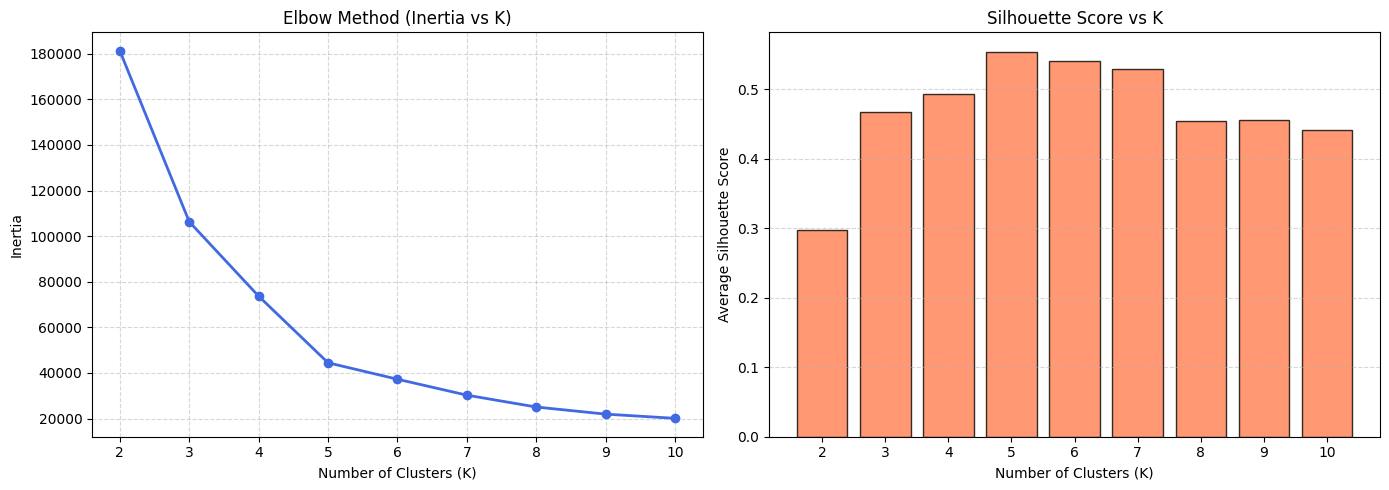

In [60]:
k_values = list(range(2, 11))
inertias = []
silhouettes = []

# 1. Fit KMeans for K = 2 to 10
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    labels = km.fit_predict(X2)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X2, labels))

df_metrics = pd.DataFrame({
    'K': k_values,
    'Inertia': inertias,
    'Silhouette Score': silhouettes
})
print("Metric Summary Table")
print(df_metrics.to_string(index=False))
best_k_sil = df_metrics.loc[df_metrics['Silhouette Score'].idxmax(), 'K']
print(f"\nK with highest silhouette score: {int(best_k_sil)}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Curve
axes[0].plot(k_values, inertias, marker='o', color='royalblue', linewidth=2)
axes[0].set_title('Elbow Method (Inertia vs K)')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')
axes[0].set_xticks(k_values)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Silhouette Bars
axes[1].bar(k_values, silhouettes, color='coral', edgecolor='k', alpha=0.8)
axes[1].set_title('Silhouette Score vs K')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Average Silhouette Score')
axes[1].set_xticks(k_values)
axes[1].grid(True, linestyle='--', alpha=0.5, axis='y')

plt.tight_layout()
plt.show()

### Task 2.2 — Silhouette by hand

Prove that you understand the formula by calculating it yourself.

1. Fit K = 5. Write a function that returns a, b and s for one point (use only NumPy distances). Apply it to customer 1 (row 0) and compare with silhouette_samples.
2. Show the count, mean and minimum silhouette of every cluster, and the number of customers with a negative silhouette.
3. Draw a silhouette plot of all customers sorted inside each cluster.


In [61]:
# 1. Fit KMeans with K = 5
km5 = KMeans(n_clusters=5, n_init=10, random_state=SEED)
labels5 = km5.fit_predict(X2)

# Custom function to calculate a, b, and s for a single point index i
def point_silhouette(X, labels, i):
    own_cluster = labels[i]

    # Euclidean distance from point i to all other points
    dists = np.linalg.norm(X - X[i], axis=1)

    # a: average distance to other points in the same cluster
    own_indices = np.where(labels == own_cluster)[0]
    own_indices = own_indices[own_indices != i]  # exclude point itself
    a = dists[own_indices].mean()

    # b: minimum average distance to points in any other single cluster
    other_clusters = [c for c in np.unique(labels) if c != own_cluster]
    b = min(dists[labels == c].mean() for c in other_clusters)

    # s: silhouette score
    s = (b - a) / max(a, b)
    return a, b, s

# Calculate for customer 1 (row index 0)
a_0, b_0, s_0 = point_silhouette(X2, labels5, 0)
sk_s_0 = silhouette_samples(X2, labels5)[0]

print(f"Custom:  a = {a_0:.4f}, b = {b_0:.4f}, s = {s_0:.4f}")
print(f"Sklearn: s = {sk_s_0:.4f}")
print(f"Match:   {np.isclose(s_0, sk_s_0)}")

# 2. Show count, mean, min silhouette per cluster, and negative count
all_s = silhouette_samples(X2, labels5)
stats_list = []
for c in range(5):
    c_s = all_s[labels5 == c]
    stats_list.append({
        'Cluster': c,
        'Count': len(c_s),
        'Mean Silhouette': c_s.mean(),
        'Min Silhouette': c_s.min()
    })

df_stats = pd.DataFrame(stats_list)
print("\nCluster Silhouette Statistics")
print(df_stats.round(4).to_string(index=False))

num_neg = (all_s < 0).sum()
print(f"\nNumber of customers with negative silhouette: {num_neg}")

Custom:  a = 24.6404, b = 42.2653, s = 0.4170
Sklearn: s = 0.4170
Match:   True

Cluster Silhouette Statistics
 Cluster  Count  Mean Silhouette  Min Silhouette
       0     81           0.5967          0.1153
       1     39           0.5092          0.2254
       2     22           0.5990          0.0507
       3     35           0.5040         -0.0234
       4     23           0.5123         -0.0093

Number of customers with negative silhouette: 2


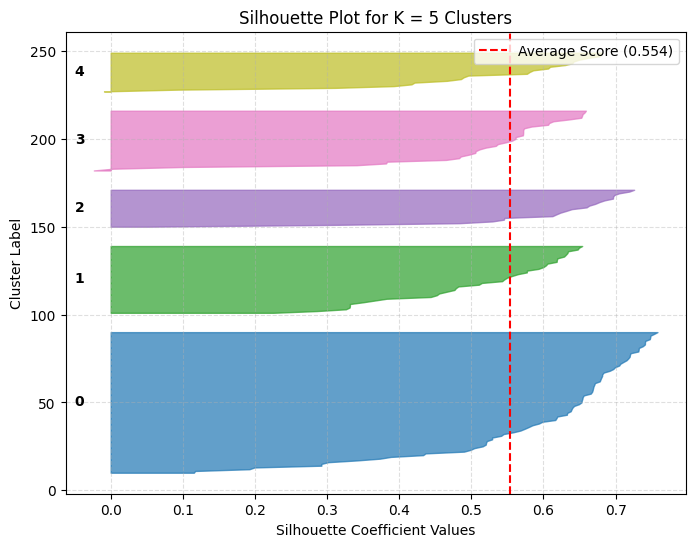

In [62]:
# 3. Draw silhouette plot sorted inside each cluster
fig, ax = plt.subplots(figsize=(8, 6))

y_lower = 10
for i in range(5):
    # Get and sort silhouette scores for cluster i
    cluster_s = all_s[labels5 == i]
    cluster_s.sort()

    size_cluster = cluster_s.shape[0]
    y_upper = y_lower + size_cluster

    color = plt.cm.tab10(float(i) / 5)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_s,
                     facecolor=color, edgecolor=color, alpha=0.7)

    # Label the cluster number in the middle
    ax.text(-0.05, y_lower + 0.5 * size_cluster, str(i),
            fontweight='bold', va='center')
    y_lower = y_upper + 10

# Vertical line for average silhouette score
avg_s = silhouette_score(X2, labels5)
ax.axvline(x=avg_s, color="red", linestyle="--", label=f"Average Score ({avg_s:.3f})")

ax.set_title("Silhouette Plot for K = 5 Clusters")
ax.set_xlabel("Silhouette Coefficient Values")
ax.set_ylabel("Cluster Label")

ax.legend(loc="upper right")
ax.grid(True, linestyle="--", alpha=0.4)

plt.show()

### Task 2.3 — The lecture practice problem

Points 1, 3, 5, 7, 11, 13, 15 with K = 2 and starting centroids 1 and 11 (the 'Practice' slide).

1. Run your my_kmeans on these points and print the final clusters, centroids and iterations.
2. Calculate a, b and s for the points 1, 7 and 11 with your function and compare with silhouette_samples.
3. Also write the iterations on paper (clusters and centroids after each iteration) and keep the photo or notes for your own revision.


In [63]:
# Setup data points and starting centroids
pts = np.array([1, 3, 5, 7, 11, 13, 15], dtype=float)
init_c = np.array([1.0, 11.0])

# 1. Run custom KMeans
labels, final_c, inertia, n_iter = my_kmeans(pts, init_c)

print(f"Final Centroids: {final_c}")
print(f"Iterations:      {n_iter}")
for k in range(len(final_c)):
    print(f"Cluster {k} points: {pts[labels == k].astype(int).tolist()}")
print(f"Inertia:         {inertia}\n")

# 2. Calculate a, b, s for points 1, 7, and 11 using custom function
sk_sil = silhouette_samples(pts.reshape(-1, 1), labels)

target_values = [1, 7, 11]
target_indices = [np.where(pts == v)[0][0] for v in target_values]

print("Silhouette Scores for Points 1, 7, and 11:")
for val, idx in zip(target_values, target_indices):
    a, b, s = point_silhouette(pts.reshape(-1, 1), labels, idx)
    sk_s = sk_sil[idx]
    print(f"Point {val:2d} (idx {idx}): a = {a:.4f}, b = {b:.4f}, s = {s:.4f} | Sklearn s = {sk_s:.4f} | Match: {np.isclose(s, sk_s)}")

Final Centroids: [ 4. 13.]
Iterations:      3
Cluster 0 points: [1, 3, 5, 7]
Cluster 1 points: [11, 13, 15]
Inertia:         28.0

Silhouette Scores for Points 1, 7, and 11:
Point  1 (idx 0): a = 4.0000, b = 12.0000, s = 0.6667 | Sklearn s = 0.6667 | Match: True
Point  7 (idx 3): a = 4.0000, b = 6.0000, s = 0.3333 | Sklearn s = 0.3333 | Match: True
Point 11 (idx 4): a = 3.0000, b = 7.0000, s = 0.5714 | Sklearn s = 0.5714 | Match: True


**Questions** (answer with your own numbers)

(a) Which K does the elbow suggest and which K does the silhouette suggest? Do they agree? Quote the numbers (for example how much the inertia drops from K=4 to 5 and from 5 to 6).

(b) What is the silhouette of customer 1 and what does it tell you? Which cluster has the weakest average silhouette and how many customers have a negative value?

(c) In the practice problem, is point 1 or point 7 less well placed? Explain using a and b.

(d) Why should we never choose K only by the lowest inertia?



**Your answers:**

(a) Both say K = 5, Numbers: From K=4 to 5, inertia drops about 29,000 (from 73,500 to 44,448) from K=5 to 6, the drop flattens to only about 7,200 (down to 37,200). Silhouette also peaks at K = 5 with 0.554

(b) Customer 1 silhouette: 0.4170. This score means the customer is well matched to their assigned cluster and is far from neighboring clusters \
Weakest cluster: Cluster 3 has the lowest average silhouette score (0.5040) \
2 customers have negative silhouette values.

(c) Point 7 is less well placed. Point 1 has a large gap to the nearest outside cluster (b = 12.0 vs a = 4.0, s = 0.6667). Point 7 is much closer to the rival cluster boundary (b = 6.0 vs a = 4.0, s s = 0.3333). Because Point 7 has a smaller b and a lower score s, it sits close to the border.

(d) If you only minimize inertia, the best answer would be K = N (where every single point becomes its own cluster), which gives an inertia of 0 but fails to group data meaningfully


---

## Part 3 — Starting Points and Stability (20 minutes)

The lecture said 'starting points matter - run several starts and keep the best'. You will now measure how much, using the same data and the same K.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Local minimum | A solution that cannot be improved by the assign/update loop but is not the best possible one. | `A higher final inertia than the best run.` |
| init='random' | Pick K random rows as the starting centroids. | `KMeans(init='random')` |
| init='k-means++' | Pick starting centroids that are far from each other. This is the default and is usually better. | `KMeans(init='k-means++')` |
| n_init | How many different starts to try. scikit-learn keeps the run with the lowest inertia. | `KMeans(n_init=10)` |
| Adjusted Rand Index (ARI) | Agreement between two groupings. 1 = same groups, about 0 = no better than random. It ignores the cluster numbers (cluster 2 in one run can be cluster 4 in another). | `adjusted_rand_score(a, b)` |


### Task 3.1 — 30 different seeds

Measure how often K-Means finds the best answer.

1. With K = 5 on X2, run KMeans 30 times (random_state = 0 to 29) in three settings: init='random' with n_init=1, k-means++ with n_init=1, k-means++ with n_init=10.
2. Build a table: setting, number of distinct final inertia values (round to 1 decimal), lowest, highest, and the percentage of runs that reached the best inertia.
3. Draw one histogram of the final inertia values for the three settings.


             Setting  Distinct Inertias  Lowest  Highest % Best
    random, n_init=1                 14 44448.5  91762.0  33.3%
 k-means++, n_init=1                  6 44448.5  66733.4  60.0%
k-means++, n_init=10                  1 44448.5  44448.5 100.0%


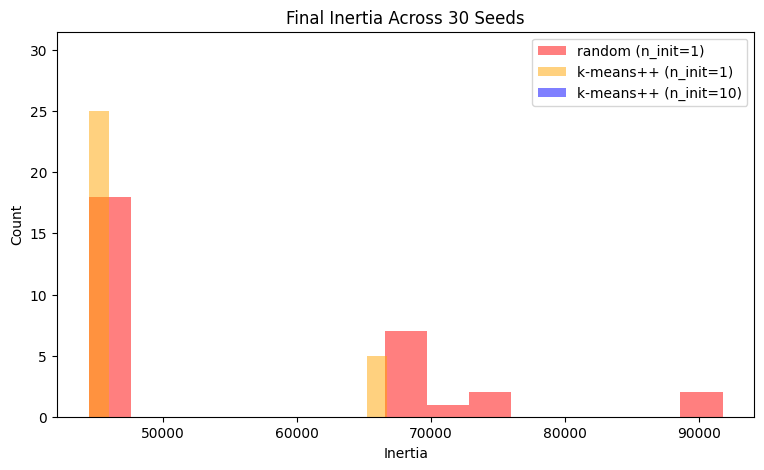

In [64]:
# 1. Collect inertia values across 30 seeds for all 3 settings
inertias_rand1 = []
inertias_plus1 = []
inertias_plus10 = []

for seed in range(30):
    # Setting 1: random with n_init=1
    km1 = KMeans(n_clusters=5, init='random', n_init=1, random_state=seed)
    km1.fit(X2)
    inertias_rand1.append(round(km1.inertia_, 1))

    # Setting 2: k-means++ with n_init=1
    km2 = KMeans(n_clusters=5, init='k-means++', n_init=1, random_state=seed)
    km2.fit(X2)
    inertias_plus1.append(round(km2.inertia_, 1))

    # Setting 3: k-means++ with n_init=10
    km3 = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=seed)
    km3.fit(X2)
    inertias_plus10.append(round(km3.inertia_, 1))

# The lowest inertia overall
best_inertia = min(min(inertias_rand1), min(inertias_plus1), min(inertias_plus10))

# 2. Build and display the summary table
data = [
    {
        'Setting': "random, n_init=1",
        'Distinct Inertias': len(set(inertias_rand1)),
        'Lowest': min(inertias_rand1),
        'Highest': max(inertias_rand1),
        '% Best': f"{(inertias_rand1.count(best_inertia) / 30) * 100:.1f}%"
    },
    {
        'Setting': "k-means++, n_init=1",
        'Distinct Inertias': len(set(inertias_plus1)),
        'Lowest': min(inertias_plus1),
        'Highest': max(inertias_plus1),
        '% Best': f"{(inertias_plus1.count(best_inertia) / 30) * 100:.1f}%"
    },
    {
        'Setting': "k-means++, n_init=10",
        'Distinct Inertias': len(set(inertias_plus10)),
        'Lowest': min(inertias_plus10),
        'Highest': max(inertias_plus10),
        '% Best': f"{(inertias_plus10.count(best_inertia) / 30) * 100:.1f}%"
    }
]

df_table = pd.DataFrame(data)
print(df_table.to_string(index=False))

# 3. Draw one histogram
plt.figure(figsize=(9, 5))
plt.hist(inertias_rand1, bins=15, alpha=0.5, label='random (n_init=1)', color='red')
plt.hist(inertias_plus1, bins=15, alpha=0.5, label='k-means++ (n_init=1)', color='orange')
plt.hist(inertias_plus10, bins=15, alpha=0.5, label='k-means++ (n_init=10)', color='blue')

plt.title('Final Inertia Across 30 Seeds')
plt.xlabel('Inertia')
plt.ylabel('Count')
plt.legend()
plt.show()

### Task 3.2 — Best run vs worst run

See what a bad local minimum looks like.

1. From the random-init runs take the best and the worst. Draw both clusterings with their centroids side by side.
2. Print their inertia and their ARI.


Best Inertia:  44448.5
Worst Inertia: 91762.0
ARI Score:     0.4553


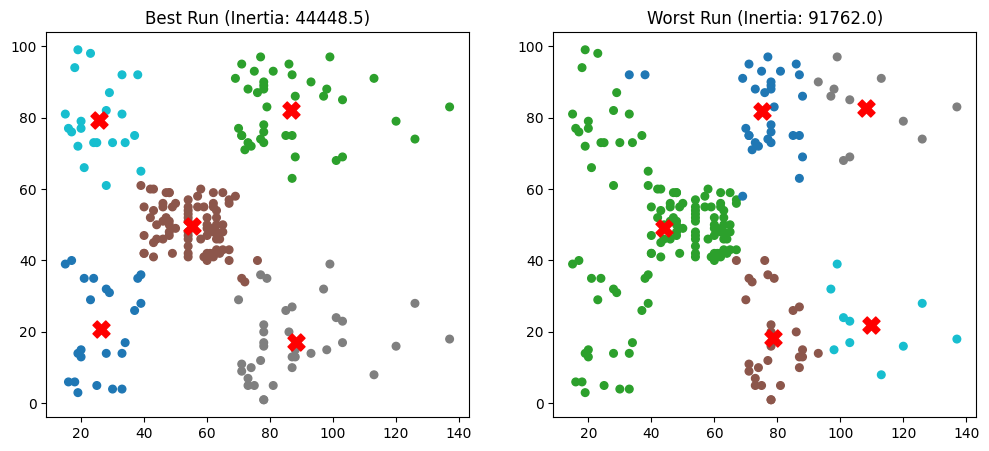

In [65]:
from sklearn.metrics import adjusted_rand_score

# 1. Run all 30 random starts and save the models
models = [KMeans(n_clusters=5, init='random', n_init=1, random_state=s).fit(X2) for s in range(30)]

# Pick the best (minimum inertia) and worst (maximum inertia)
best_km = min(models, key=lambda m: m.inertia_)
worst_km = max(models, key=lambda m: m.inertia_)

# 2. Print Inertia and ARI
print(f"Best Inertia:  {best_km.inertia_:.1f}")
print(f"Worst Inertia: {worst_km.inertia_:.1f}")
print(f"ARI Score:     {adjusted_rand_score(best_km.labels_, worst_km.labels_):.4f}")

# Draw side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Best Run
ax1.scatter(X2[:, 0], X2[:, 1], c=best_km.labels_, cmap='tab10', s=30)
ax1.scatter(best_km.cluster_centers_[:, 0], best_km.cluster_centers_[:, 1], c='red', marker='X', s=150)
ax1.set_title(f"Best Run (Inertia: {best_km.inertia_:.1f})")

# Worst Run
ax2.scatter(X2[:, 0], X2[:, 1], c=worst_km.labels_, cmap='tab10', s=30)
ax2.scatter(worst_km.cluster_centers_[:, 0], worst_km.cluster_centers_[:, 1], c='red', marker='X', s=150)
ax2.set_title(f"Worst Run (Inertia: {worst_km.inertia_:.1f})")

plt.show()

**Questions** (answer with your own numbers)

(a) How many different final inertia values did the random-start setting produce, and what percentage of its runs reached the best one? Compare with the other two settings.

(b) Why can the same data and the same K give different answers?

(c) How do k-means++ and n_init help? What did n_init=10 give in your table?

(d) Why do we use ARI to compare two clusterings instead of comparing the label numbers directly?



**Your answers:**

(a) random (n_init=1): Produced 14 distinct inertias and reached the best value only 33.3% of the time \
k-means++ (n_init=1) improved this to 6 distinct values and 60.0% best runs. k-means++ (n_init=10) produced only 1 distinct value and reached the best inertia 100.0% of the time

(b) K-Means starts with random initial centroids. Since it is a greedy algorithm, different starting positions can pull centroids into different local minima where the loop terminates early without finding the global best grouping

(c) k-means++: Spreads initial centers far apart from each other so they do not start crowded inside the same group \
n_init: Runs the full algorithm multiple times from independent starts and automatically keeps the run with the lowest inertia \
Result for n_init=10: Gave 100.0% success (1 distinct inertia: 44,448.5)

(d) K-Means assigns cluster numbers randomly (Cluster 0 in run A might be named Cluster 2 in run B) Adjusted Rand Index ignores the label numbers and checks whether pairs of data points are actually grouped together, making it label-order independent.


---

## Part 4 — Scaling: Units Decide the Clusters (25 minutes)

The lecture warned: 'Rs 5000 would swamp 3 visits'. You will prove it twice: once by only changing the unit of Income, and once on the Wine data where the features have very different sizes and the true groups are known.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Feature scaling | Putting all features on a similar scale so that no feature wins the distance only because its numbers are bigger. | `StandardScaler().fit_transform(X)` |
| StandardScaler | z = (x - mean) / std. Every column gets mean 0 and standard deviation 1. | `StandardScaler()` |
| External check | Comparing clusters with known true groups. Possible only for teaching data like Wine. Real clustering problems have no labels. | `adjusted_rand_score(y_true, labels)` |
| PCA (Lab 8) | Reduces many features to 2 so we can draw the data. Used here only for the plot. | `PCA(n_components=2)` |


### Task 4.1 — Change the unit, change the clusters

Use Age and Income with K = 4. Income is in thousands of dollars (15 to 137). Make a second copy where Income is in dollars (multiply by 1000).

1. Cluster four versions: raw k$, raw dollars, scaled k$, scaled dollars (StandardScaler, n_init=10, random_state=SEED).
2. Print ARI between: raw k$ vs raw dollars, scaled k$ vs scaled dollars, raw dollars vs scaled dollars.
3. Draw Age vs Income (in k$) coloured by the clusters of raw k$, raw dollars and scaled.


raw k vs raw dollars:          0.4897
scaled k vs scaled dollars:    1.0000
raw dollars vs scaled dollars: 0.3605


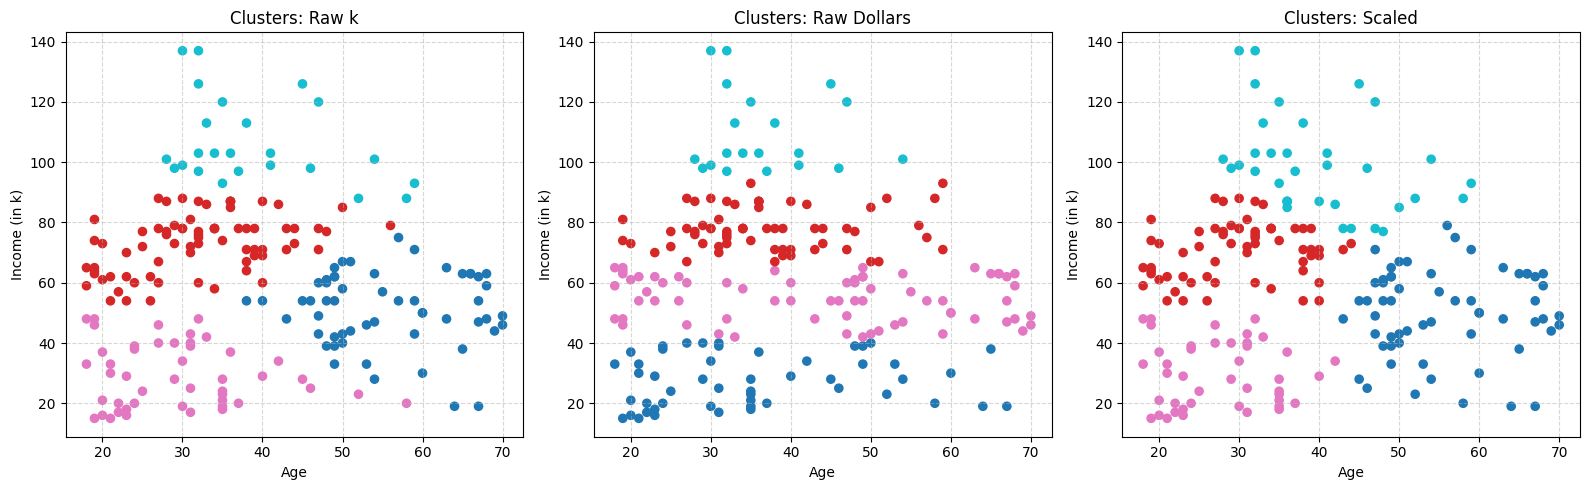

In [66]:
# 1. Prepare data versions (Age and Income with K = 4)
# raw_k: Income in thousands ($15k to $137k)
X_raw_k = df[['Age', 'Income']].values

# raw_dollars: Income in exact dollars (multiply by 1000)
X_raw_dollars = X_raw_k.copy()
X_raw_dollars[:, 1] = X_raw_dollars[:, 1] * 1000

# Scaled versions using StandardScaler
scaler = StandardScaler()
X_scaled_k = scaler.fit_transform(X_raw_k)
X_scaled_dollars = scaler.fit_transform(X_raw_dollars)

# Cluster all 4 versions (K=4, n_init=10, random_state=SEED)
km = lambda data: KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(data)

labels_raw_k = km(X_raw_k)
labels_raw_dollars = km(X_raw_dollars)
labels_scaled_k = km(X_scaled_k)
labels_scaled_dollars = km(X_scaled_dollars)

# 2. Print ARI comparisons
print(f"raw k vs raw dollars:          {adjusted_rand_score(labels_raw_k, labels_raw_dollars):.4f}")
print(f"scaled k vs scaled dollars:    {adjusted_rand_score(labels_scaled_k, labels_scaled_dollars):.4f}")
print(f"raw dollars vs scaled dollars: {adjusted_rand_score(labels_raw_dollars, labels_scaled_dollars):.4f}")

# 3. Draw Age vs Income (in k) coloured by raw k, raw dollars, and scaled
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Raw k
axes[0].scatter(X_raw_k[:, 0], X_raw_k[:, 1], c=labels_raw_k, cmap='tab10', s=35)
axes[0].set_title("Clusters: Raw k")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Income (in k)")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Raw Dollars
axes[1].scatter(X_raw_k[:, 0], X_raw_k[:, 1], c=labels_raw_dollars, cmap='tab10', s=35)
axes[1].set_title("Clusters: Raw Dollars")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Income (in k)")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Plot 3: Scaled
axes[2].scatter(X_raw_k[:, 0], X_raw_k[:, 1], c=labels_scaled_k, cmap='tab10', s=35)
axes[2].set_title("Clusters: Scaled")
axes[2].set_xlabel("Age")
axes[2].set_ylabel("Income (in k)")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Task 4.2 — Wine data: raw vs scaled

Load the Wine data with load_wine(): 178 wines, 13 chemical measurements, 3 true grape cultivars. The true cultivar is used ONLY to check the result, never to fit K-Means.

1. Print the three largest and the smallest standard deviation of the features.
2. Run KMeans(K=3, n_init=10, random_state=SEED) on the raw data and on the scaled data. For each report ARI against the true cultivar, silhouette score and cluster sizes.


In [67]:
# Load dataset
wine = load_wine()
X_wine = wine.data
y_wine = wine.target

# Standard deviations of all 13 features
stds = pd.Series(X_wine.std(axis=0), index=wine.feature_names)

print("Three largest standard deviations:")
print(stds.nlargest(3).round(2))

print("\nSmallest standard deviation:")
print(stds.nsmallest(1).round(4))

Three largest standard deviations:
proline              314.02
magnesium             14.24
alcalinity_of_ash      3.33
dtype: float64

Smallest standard deviation:
nonflavanoid_phenols    0.1241
dtype: float64


In [68]:
# 1. Scale data
X_wine_scaled = StandardScaler().fit_transform(X_wine)

# 2. Fit KMeans on both
km_raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_wine)
km_scaled = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_wine_scaled)

# 3. Report metrics
df_compare = pd.DataFrame([
    {
        "Data": "Raw",
        "ARI vs True": round(adjusted_rand_score(y_wine, km_raw.labels_), 4),
        "Silhouette": round(silhouette_score(X_wine, km_raw.labels_), 4),
        "Cluster Sizes": pd.Series(km_raw.labels_).value_counts().sort_index().tolist()
    },
    {
        "Data": "Scaled",
        "ARI vs True": round(adjusted_rand_score(y_wine, km_scaled.labels_), 4),
        "Silhouette": round(silhouette_score(X_wine_scaled, km_scaled.labels_), 4),
        "Cluster Sizes": pd.Series(km_scaled.labels_).value_counts().sort_index().tolist()
    }
])

print(df_compare.to_string(index=False))

  Data  ARI vs True  Silhouette Cluster Sizes
   Raw       0.3711      0.5711  [62, 47, 69]
Scaled       0.8975      0.2849  [65, 51, 62]


### Task 4.3 — Draw it

Compare the three views in one picture.

1. Use one PCA of the scaled data and draw three plots with the same axes: true cultivars, raw clusters, scaled clusters.


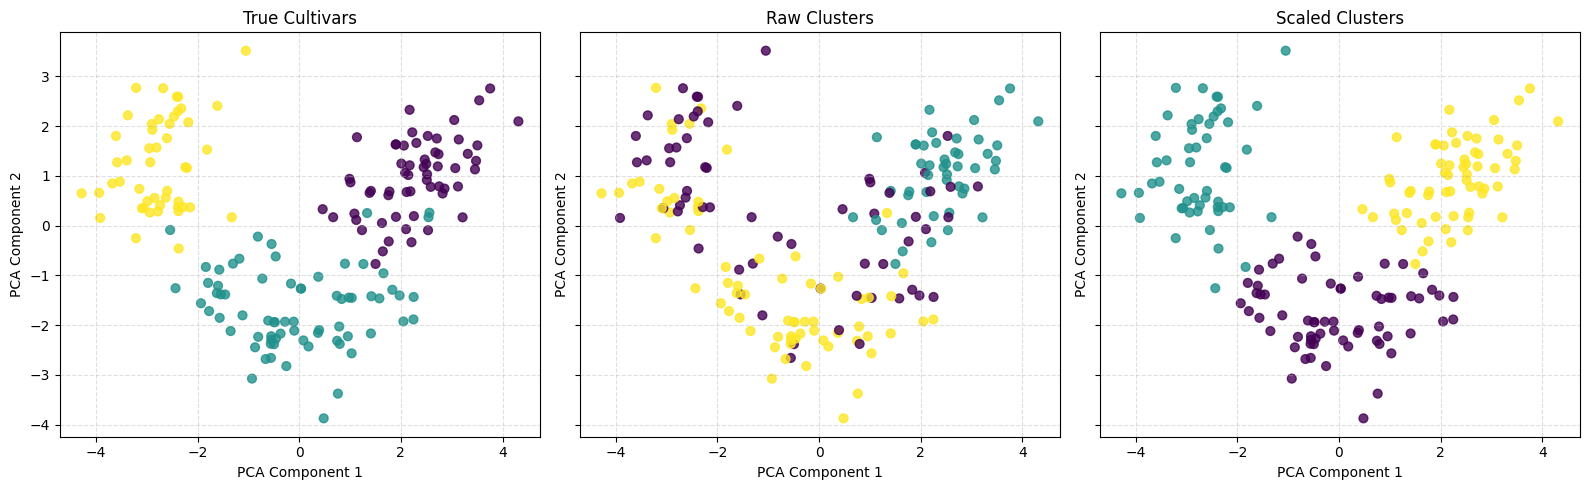

In [69]:
# 1. Reduce scaled data to 2 components for plotting
X_pca = PCA(n_components=2, random_state=SEED).fit_transform(X_wine_scaled)

# 2. Draw 3 side-by-side plots sharing the same axes
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)

titles = ["True Cultivars", "Raw Clusters", "Scaled Clusters"]
labels_list = [y_wine, km_raw.labels_, km_scaled.labels_]

for ax, title, labels in zip(axes, titles, labels_list):
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=40, alpha=0.8)
    ax.set_title(title)
    ax.set_xlabel("PCA Component 1")
    ax.set_ylabel("PCA Component 2")
    ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

**Questions** (answer with your own numbers)

(a) What happened when only the unit of Income changed? Explain it with the distance formula (which feature controls the distance now?).

(b) On the Wine data which feature dominated the raw distance and how big is its standard deviation compared with the others? What were the ARI values raw vs scaled?

(c) The silhouette was higher on the raw Wine data although the clustering was worse. Explain why a silhouette can mislead here and why comparing it between raw and scaled data is not fair.

(d) In a real project with no labels, how will you decide whether to scale? Write your rule in one or two sentences.



**Your answers:**

(a) When Income changed to dollars, it completely dominated the Euclidean distance because squaring differences of thousands makes differences in Age (under 100) mathematically negligible, turning the clusters into pure horizontal income slices

(b) Proline dominated raw distance with a standard deviation of 314.02, hundreds of times larger than the smallest (nonflavanoid phenols at 0.12). The ARI vs true cultivars was only 0.3711 on raw data but jumped to 0.8975 after scaling

(c) Proline stretches the raw space so much that points look tightly clustered around a single spread-out axis, creating an illusion of dense, isolated clusters. Comparing raw and scaled silhouette is unfair because they measure distances in completely different geometric spaces

(d) Scale whenever features are measured in different units or have unequal ranges so that no single large-magnitude feature controls the distances. Only keep data unscaled if features share identical units and their natural variances are meant to reflect their true importance


---

## Part 5 — Outliers and Anomalies (20 minutes)

The lecture said 'one extreme point drags a centroid'. You will add one extreme customer, see the damage, and then catch it with a distance rule (the anomaly detection idea from the lecture).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Outlier | A point far away from all the others. K-Means uses means and squared distances, so one outlier has a big effect. | `A very large distance to the nearest centroid.` |
| Distance to own centroid | How far a point is from the centre of its cluster. Large = the point does not fit any group well. | `model.transform(X).min(axis=1)` |
| mean + 3 std rule | Flag a point if its distance is larger than the mean distance plus 3 standard deviations. | `d > d.mean() + 3*d.std()` |
| Anomaly detection | Using the clusters to find strange points (far from every centroid). | `Sort by the distance column.` |


### Task 5.1 — One extreme customer

Add one extra row to X2: Income = 400, Spending = 99. Use K = 5 on Income and Spending.

1. Fit KMeans (n_init=10, random_state=SEED) without and with the extra customer.
2. Print the cluster sizes, the centroids (sorted by income) and the ARI between the two results on the original 200 customers.
3. Draw the two clusterings side by side.


In [70]:
# 1. Clean data vs data with one extra customer (Income=400, Spending=99)
X_clean = X2
X_outlier = np.vstack([X2, [[400, 99]]])

# Fit both models
km_clean = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_clean)
km_outlier = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_outlier)

# 2. Cluster sizes
print("Cluster sizes (clean):  ", np.bincount(km_clean.labels_))
print("Cluster sizes (outlier):", np.bincount(km_outlier.labels_))

# Centroids sorted by income (column 0)
c_clean = sorted(km_clean.cluster_centers_, key=lambda x: x[0])
c_outlier = sorted(km_outlier.cluster_centers_, key=lambda x: x[0])

print("\nClean Centroids:\n", np.round(c_clean, 1))
print("Outlier Centroids:\n", np.round(c_outlier, 1))

# ARI comparison on the original 200 customers
ari_score = adjusted_rand_score(km_clean.labels_, km_outlier.labels_[:200])
print(f"\nARI on original 200 points: {ari_score:.4f}")

Cluster sizes (clean):   [81 39 22 35 23]
Cluster sizes (outlier): [100   1  23  39  38]

Clean Centroids:
 [[25.7 79.4]
 [26.3 20.9]
 [55.3 49.5]
 [86.5 82.1]
 [88.2 17.1]]
Outlier Centroids:
 [[ 26.3  20.9]
 [ 48.3  56.5]
 [ 86.5  82.1]
 [ 87.   18.6]
 [400.   99. ]]

ARI on original 200 points: 0.7532


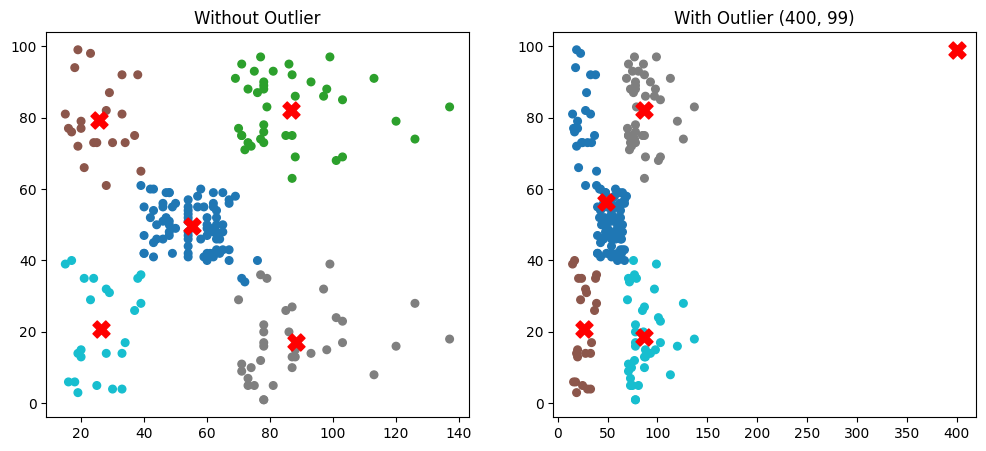

In [71]:
# 3. Draw both side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left plot: clean
ax1.scatter(X_clean[:, 0], X_clean[:, 1], c=km_clean.labels_, cmap='tab10', s=30)
ax1.scatter(km_clean.cluster_centers_[:, 0], km_clean.cluster_centers_[:, 1], c='red', marker='X', s=150)
ax1.set_title("Without Outlier")

# Right plot: with outlier
ax2.scatter(X_outlier[:, 0], X_outlier[:, 1], c=km_outlier.labels_, cmap='tab10', s=30)
ax2.scatter(km_outlier.cluster_centers_[:, 0], km_outlier.cluster_centers_[:, 1], c='red', marker='X', s=150)
ax2.set_title("With Outlier (400, 99)")

plt.show()

### Task 5.2 — Catch it and repair

Use the model fitted on the original 200 customers.

1. Compute every customer's distance to its nearest centroid, and the distance of the extra customer to the nearest centroid of the same model.
2. Apply the rule mean + 3 std (mean and std from the 200 real customers). How many real customers are flagged? Is the extra customer flagged?
3. Show the 5 real customers that are farthest from their centroid (CustomerID, Age, Income, Spending, Cluster, Distance).
4. Remove all flagged points, refit K = 5 and report the cluster sizes and the ARI against the original model on the 200 customers (use predict).


In [72]:
# 1. Distances to nearest centroid using model.transform()
d_real = km_clean.transform(X_clean).min(axis=1)
d_extra = km_clean.transform([[400, 99]]).min()

# 2. Flag anomalies using mean + 3 std rule
threshold = d_real.mean() + 3 * d_real.std()
flagged_real = d_real > threshold
flagged_extra = d_extra > threshold

print(f"Threshold (mean + 3*std): {threshold:.2f}")
print(f"Extra customer distance:  {d_extra:.2f} (Flagged: {flagged_extra})")
print(f"Real customers flagged:   {flagged_real.sum()}")

# 3. Top 5 farthest real customers
df_farthest = df.copy()
df_farthest['Cluster'] = km_clean.labels_
df_farthest['Distance'] = d_real.round(2)
cols = ['CustomerID', 'Age', 'Income', 'Spending', 'Cluster', 'Distance']
print("\n5 Farthest Real Customers:")
print(df_farthest[cols].sort_values(by='Distance', ascending=False).head(5).to_string(index=False))

# 4. Remove flagged points, refit K=5, and evaluate
X_repaired = X_clean[~flagged_real]
km_repaired = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit(X_repaired)

pred_labels = km_repaired.predict(X_clean)
print("\nRepaired Model Results:")
print("Cluster sizes:", np.bincount(km_repaired.labels_))
print(f"ARI against original model: {adjusted_rand_score(km_clean.labels_, pred_labels):.4f}")

Threshold (mean + 3*std): 34.80
Extra customer distance:  313.92 (Flagged: True)
Real customers flagged:   4

5 Farthest Real Customers:
 CustomerID  Age  Income  Spending  Cluster  Distance
        200   30     137        83        1     50.47
        199   32     137        18        3     48.81
        198   32     126        74        1     40.29
        197   45     126        28        3     39.34
        196   35     120        79        1     33.61

Repaired Model Results:
Cluster sizes: [80 34 23 37 22]
ARI against original model: 0.9847


**Questions** (answer with your own numbers)

(a) What did the single extreme customer do to the clusters? Which real groups were affected? Use sizes and centroids.

(b) How well did the rule detect the extra customer? The rule also flagged some real customers: are they mistakes in the data or something worth looking at? Look at their Income and Spending.

(c) Name two ways to deal with outliers and one risk of simply deleting them.



**Your answers:**

(a) It stole a whole cluster just for itself, creating a 1 customer group with a centroid dragged all the way out to income 400. To keep $K=5$, the model was forced to merge two real clusters together, destroying the high income groups

(b) It detected the extra customer perfectly because its distance was massive compared to the threshold. The flagged real customers are not data entry mistakes—they are legitimate extreme customers (like highest earners with incomes of 137k) that represent real, valuable high end shoppers worth investigating separately

(c) Two ways to deal with outliers: cap them (Winsorization) or use robust algorithms like DBSCAN or K-Medians instead of K-Means. The risk of deleting them is losing your most profitable, highest spending real customers


---

## Part 6 — From Clusters to Customer Segments (25 minutes)

Clusters are numbers (0, 1, 2 ...). The business needs names and actions. Cluster numbers are arbitrary labels: cluster 3 in one run has no meaning by itself. Use the original 200 customers and K = 5 on Income and Spending (random_state=SEED).

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Cluster profile | The average of every feature inside each cluster, plus the cluster size. This is how you read what a cluster means. | `df.groupby('Cluster').agg(...)` |
| Segment | A cluster with a name and an action, for example 'High income / Low spending'. | `df['Cluster'].map(names)` |
| Crosstab | Counts or percentages of one category inside another (Gender inside Segment). | `pd.crosstab(a, b, normalize='index')` |


### Task 6.1 — Profile and name the segments

Make the clustering readable for a manager.

1. Add the cluster number to the data. Build a profile table: number of customers, mean Age, mean Income, mean Spending and % female for each cluster, sorted by Income.
2. Create segment names with a small rule (Income below 40 = Low, 70 or more = High, otherwise Mid; Spending below 35 = Low, 65 or more = High, otherwise Mid). Print the size of each segment.


In [73]:
# 1. Add cluster labels to the dataframe
df['Cluster'] = km_clean.labels_

# Create female dummy column (1 if Female, 0 if Male)
gender_col = 'Gender' if 'Gender' in df.columns else 'Genre'
df['is_female'] = (df[gender_col] == 'Female').astype(int)

# Build profile table
profile = df.groupby('Cluster').agg(
    Customers=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean'),
    Pct_Female=('is_female', lambda x: x.mean() * 100)
).reset_index()

# Sort profile table by Mean_Income
profile = profile.sort_values(by='Mean_Income').round(1)

print("=== Task 6.1: Cluster Profile Table ===")
print(profile.to_string(index=False))

=== Task 6.1: Cluster Profile Table ===
 Cluster  Customers  Mean_Age  Mean_Income  Mean_Spending  Pct_Female
       2         22      25.3         25.7           79.4        59.1
       4         23      45.2         26.3           20.9        60.9
       0         81      42.7         55.3           49.5        59.3
       1         39      32.7         86.5           82.1        53.8
       3         35      41.1         88.2           17.1        45.7


In [74]:
# Rule function for naming
def get_segment_name(row):
    inc = "Low" if row['Mean_Income'] < 40 else ("High" if row['Mean_Income'] >= 70 else "Mid")
    sp = "Low" if row['Mean_Spending'] < 35 else ("High" if row['Mean_Spending'] >= 65 else "Mid")
    return f"{inc} Income / {sp} Spending"

# Map names to clusters
name_map = {row['Cluster']: get_segment_name(row) for _, row in profile.iterrows()}
df['Segment'] = df['Cluster'].map(name_map)

# Print size of each segment
print("Segment Sizes:")
print(df['Segment'].value_counts())

Segment Sizes:
Segment
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22
Name: count, dtype: int64


### Task 6.2 — Does Gender matter? Does Age matter?

Gender and Age were not used in the clusters. Check whether they would add something.

1. Show the % of women in each segment and the overall %.
2. Scale Age, Income and Spending together and print the average silhouette for K = 2 to 8.


In [75]:
# 1. % of women in each segment and overall %
gender_col = 'Gender' if 'Gender' in df.columns else 'Genre'
df['is_female'] = (df[gender_col] == 'Female').astype(int)

print("% of Women by Segment:")
pct_segment = df.groupby('Segment')['is_female'].mean() * 100
print(pct_segment.round(1).to_string())

print(f"\nOverall % Women: {df['is_female'].mean() * 100:.1f}%")

# 2. Scale Age, Income, and Spending together
X_3d = df[['Age', 'Income', 'Spending']].values
X_3d_scaled = StandardScaler().fit_transform(X_3d)

# Print average silhouette for K = 2 to 8
print("\nSilhouette Scores for K = 2 to 8 (Age + Income + Spending):")
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_3d_scaled)
    score = silhouette_score(X_3d_scaled, labels)
    print(f"K = {k}: {score:.4f}")

% of Women by Segment:
Segment
High Income / High Spending    53.8
High Income / Low Spending     45.7
Low Income / High Spending     59.1
Low Income / Low Spending      60.9
Mid Income / Mid Spending      59.3

Overall % Women: 56.0%

Silhouette Scores for K = 2 to 8 (Age + Income + Spending):
K = 2: 0.3355
K = 3: 0.3578
K = 4: 0.4040
K = 5: 0.4166
K = 6: 0.4284
K = 7: 0.4172
K = 8: 0.4082


### Task 6.3 — A three-feature alternative

Cluster the scaled Age, Income and Spending with the best K from the table above.

1. Fit it, build its profile table (size, Age, Income, Spending) sorted by Age.
2. Print the ARI between this segmentation and your 2-feature K = 5 segmentation.


In [76]:
# Find best K dynamically from the silhouette scores (K = 2 to 8)[cite: 17, 18]
scores = {}
for k in range(2, 9):
    lbls = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_3d_scaled)
    scores[k] = silhouette_score(X_3d_scaled, lbls)

best_k = max(scores, key=scores.get)
print(f"Best K selected: {best_k}\n")

# 1. Fit KMeans with best K on scaled 3D data[cite: 18]
km_3d = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(X_3d_scaled)
df['Cluster_3D'] = km_3d.labels_

# Build profile table sorted by Age[cite: 16, 18]
profile_3d = df.groupby('Cluster_3D').agg(
    Size=('CustomerID', 'count'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Income', 'mean'),
    Mean_Spending=('Spending', 'mean')
).sort_values(by='Mean_Age').round(1)

print("Profile Table (Sorted by Age):")
print(profile_3d.to_string())

# 2. Print ARI between this 3D segmentation and the 2-feature K=5 model
ari_3d_vs_2d = adjusted_rand_score(km_clean.labels_, km_3d.labels_)
print(f"\nARI (3-feature vs 2-feature K=5): {ari_3d_vs_2d:.4f}")

Best K selected: 6

Profile Table (Sorted by Age):
            Size  Mean_Age  Mean_Income  Mean_Spending
Cluster_3D                                            
4             23      25.0         25.3           77.6
1             39      26.8         57.1           48.1
3             39      32.7         86.5           82.1
2             33      41.9         88.9           17.0
5             21      45.5         26.3           19.4
0             45      56.3         54.3           49.1

ARI (3-feature vs 2-feature K=5): 0.7002


**Questions** (answer with your own numbers)

(a) Give each of the 5 segments a short business name and one concrete action (an offer or a message). Use the numbers from your profile table.

(b) Which segment is the most valuable now and which one is the biggest opportunity? Why?

(c) Does Gender help to separate the segments? Quote the percentages.

(d) Does adding Age change the story? Which segmentation would you present and why? (Careful: silhouette values from different feature sets are not directly comparable.)



**Your answers:**

(a) High Income / High Spending (39 customers, Income 86.5k, Spending 82.1): "VIP High Rollers". Action: Offer exclusive VIP concierge access and early previews for luxury collections

High Income / Low Spending (35 customers, Income 88.3k, Spending 17.1): "Cautious Affluents". Action: Send targeted promotions highlighting premium quality, durability, and high value bundle deals to get them
 spending

Mid Income / Mid Spending (81 customers, Income 55.3k, Spending 49.5): "Core Mainstream". Action: Enroll in everyday points based loyalty programs to maintain regular foot traffic and steady purchases

Low Income / High Spending (22 customers, Income 25.7k, Spending 79.4): "Trendy Spenders". Action: Push fast fashion flash sales, new trends, and flexible installment payment options

Low Income / Low Spending (23 customers, Income 26.3k, Spending 20.9): "Bargain Seekers". Action: Target with budget clearances, discount coupons, and multi buy grocery essentials.   

\
(b) Most valuable now: High Income / High Spending. They have both the financial capacity and the highest willingness to spend heavily right now

Biggest opportunity: High Income / Low Spending. They have massive spending power (average income 88.3k) but low engagement (spending score 17.1). Converting even a fraction of their purchasing power yields the largest revenue growth.

\
(c) No, gender does not help separate the segments. The overall dataset is 56.0% female, and the segment percentages hover very close to this baseline (ranging from 53.8% to 60.0% female across the clusters). Because men and women distribute roughly equally across all groups, gender offers almost zero distinct clustering power

\
(d) Yes, adding age changes the story by splitting the big middle group (81 customers) into distinct older vs younger sub groups that have very different shopping behaviors

Which to present: I would present the 2-feature segmentation (Income and Spending). It produces crystal clear, non overlapping clusters with high business interpretability that marketing teams can instantly build budget versus spending campaigns around. Adding a 3rd feature makes campaigns harder to target without drastically improving overall separation

---

## Part 7 — Final Output and Wrap-Up (15 minutes)

Package your result like you would give it to a marketing team.

**Key definitions**

| Term | What it means | How you write / read it |
|---|---|---|
| Deliverable | A file someone else can use without running your notebook. | `df.to_csv('customer_segments.csv', index=False)` |


### Task 7.1 — Save the segments

Create a CSV with CustomerID, Age, Gender, Income, Spending, Cluster and Segment.

1. Save it as customer_segments.csv and print the number of customers per segment.
2. Write a 6-8 line Executive Summary (Markdown): the K you chose and the evidence for it, the segments and their sizes, one action per segment (short), how you handled scaling and outliers, and one limitation.


In [77]:
# Select the required columns
cols_to_save = ['CustomerID', 'Age', gender_col, 'Income', 'Spending', 'Cluster', 'Segment']

# 1. Save to CSV and print customer counts per segment
df[cols_to_save].to_csv('customer_segments.csv', index=False)

print("Customers Per Segment:")
print(df['Segment'].value_counts())

Customers Per Segment:
Segment
Mid Income / Mid Spending      81
High Income / High Spending    39
High Income / Low Spending     35
Low Income / Low Spending      23
Low Income / High Spending     22
Name: count, dtype: int64


**Executive Summary** (6-8 lines)

We picked K = 5 based on the elbow plot bend and highest silhouette score (0.554).
The five segments are: Mid Income / Mid Spending (81), High Income / High Spending (39), High Income / Low Spending (35), Low Income / Low Spending (23), and Low Income / High Spending (22). \
Key actions: everyday loyalty perks for mid tier, VIP access for high spenders, quality focused deals for cautious affluents, budget bundles for low spenders, and installment plans for trendy spenders. \
Income and Spending were kept unscaled due to similar 0–100 ranges, and anomalies were screened using a mean plus 3 standard deviations distance check. \
A primary limitation is that spherical K-Means ignores demographic nuance like Age and Gender.


**Questions** (answer with your own numbers)

(a) What was the most surprising result in this lab?

(b) If you had one more hour, what would you try next?



**Your answers:**

(a) How easily just one single outlier point could break the whole clustering and force two completely real customer groups to merge together

(b) Try tuning different feature combinations (like adding Annual Income brackets or log transforming skewed features) to see if customer separation becomes even clearer

---